<a href="https://colab.research.google.com/github/vjshivani25-hub/DLAC/blob/main/skill5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pycocotools opencv-python matplotlib pandas seaborn -q

print("Libraries installed successfully!")

Libraries installed successfully!


In [2]:
import os
import json
import glob
import cv2
import random
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from google.colab import files
from pycocotools.coco import COCO

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
uploaded = files.upload()

zip_file = list(uploaded.keys())[0]

print("Uploaded file:", zip_file)

Saving traffic_rush_sample_dataset.zip to traffic_rush_sample_dataset.zip
Uploaded file: traffic_rush_sample_dataset.zip


In [4]:
extract_path = "/content/traffic_dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset uploaded and extracted successfully!")

Dataset uploaded and extracted successfully!


In [5]:
json_files = glob.glob(
    extract_path + "/**/*.json",
    recursive=True
)

print("JSON files found:", json_files)

JSON files found: ['/content/traffic_dataset/annotations.json']


In [6]:
if not json_files:
    raise FileNotFoundError("COCO JSON annotation file not found!")

annotation_file = json_files[0]

with open(annotation_file, "r") as f:
    coco_data = json.load(f)

print("Annotation data loaded successfully!")

Annotation data loaded successfully!


In [7]:
print("COCO Dataset Information")
print("------------------------")

print("Images:", len(coco_data["images"]))
print("Annotations:", len(coco_data["annotations"]))
print("Categories:", len(coco_data["categories"]))

COCO Dataset Information
------------------------
Images: 30
Annotations: 173
Categories: 6


In [8]:
categories = coco_data["categories"]

category_names = {
    category["id"]: category["name"]
    for category in categories
}

print("TRAFFIC OBJECT CATEGORIES")
print("-------------------------")

for category in categories:
    print("ID:", category["id"],
          "| Name:", category["name"])

TRAFFIC OBJECT CATEGORIES
-------------------------
ID: 1 | Name: car
ID: 2 | Name: bus
ID: 3 | Name: truck
ID: 4 | Name: motorcycle
ID: 5 | Name: bicycle
ID: 6 | Name: person


In [9]:
category_counts = Counter()

for annotation in coco_data["annotations"]:

    category_id = annotation["category_id"]

    category_counts[
        category_names[category_id]
    ] += 1

print(category_counts)

Counter({'car': 57, 'person': 27, 'bus': 26, 'motorcycle': 25, 'truck': 21, 'bicycle': 17})


In [10]:
df = pd.DataFrame(
    category_counts.items(),
    columns=["Traffic Category", "Number of Objects"]
)

print(df)

  Traffic Category  Number of Objects
0            truck                 21
1              car                 57
2           person                 27
3       motorcycle                 25
4              bus                 26
5          bicycle                 17


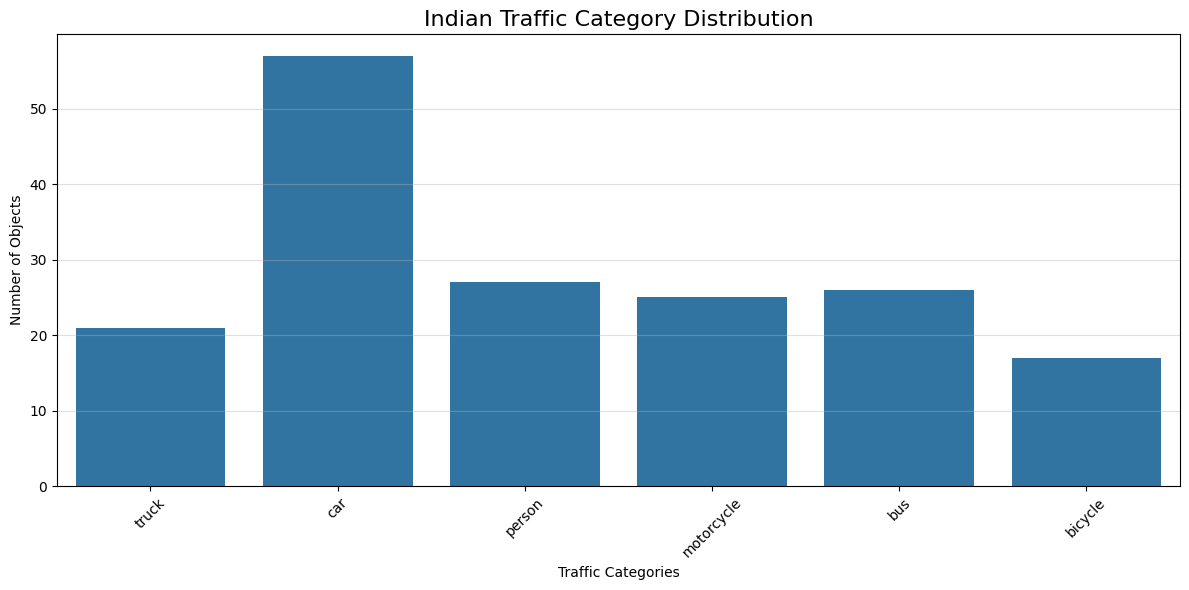

In [11]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x="Traffic Category",
    y="Number of Objects"
)

plt.title("Indian Traffic Category Distribution", fontsize=16)
plt.xlabel("Traffic Categories")
plt.ylabel("Number of Objects")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.4)

plt.tight_layout()
plt.show()

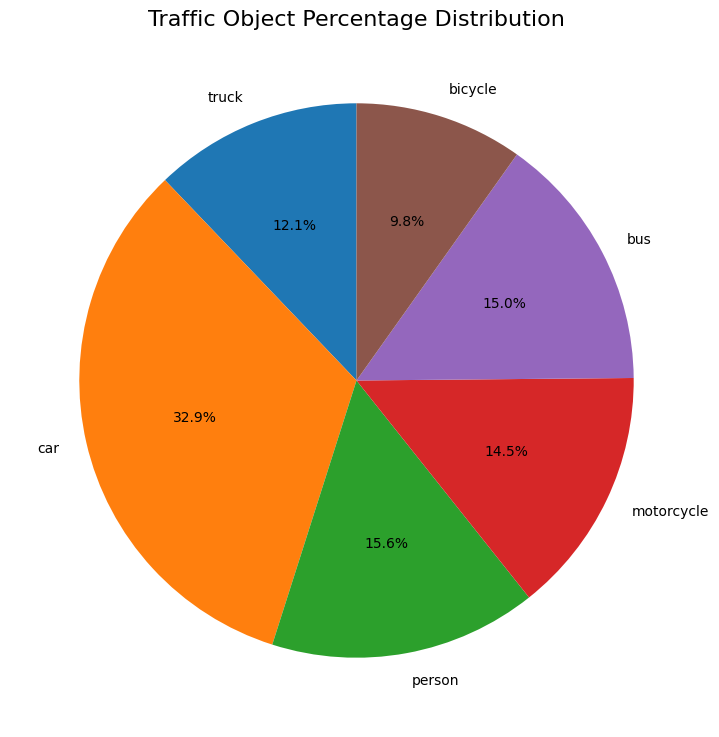

In [12]:
plt.figure(figsize=(9, 9))

plt.pie(
    df["Number of Objects"],
    labels=df["Traffic Category"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Traffic Object Percentage Distribution", fontsize=16)

plt.show()

In [13]:
image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

image_map = {}

for root, dirs, filenames in os.walk(extract_path):

    for filename in filenames:

        if filename.lower().endswith(image_extensions):

            image_map[filename] = os.path.join(
                root, filename
            )

print("Total images found:", len(image_map))

Total images found: 30


In [15]:
def visualize_image(image_id):

    image_info = next(
        img for img in coco_data["images"]
        if img["id"] == image_id
    )

    filename = os.path.basename(image_info["file_name"])

    image_path = image_map.get(filename)

    if image_path is None:
        print("Image not found:", filename)
        return

    image = cv2.imread(image_path)

    if image is None:
        print("Unable to read image!")
        return

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    annotations = [
        ann for ann in coco_data["annotations"]
        if ann["image_id"] == image_id
    ]

    for ann in annotations:

        x, y, w, h = map(int, ann["bbox"])

        label = category_names[ann["category_id"]]

        cv2.rectangle(
            image,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

        cv2.putText(
            image,
            label,
            (x, max(y - 5, 15)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255, 0, 0),
            2
        )

    plt.figure(figsize=(12, 7))
    plt.imshow(image)
    plt.title("Traffic Image with Bounding Boxes")
    plt.axis("off")
    plt.show()

    print("Image:", filename)
    print("Total Objects:", len(annotations))

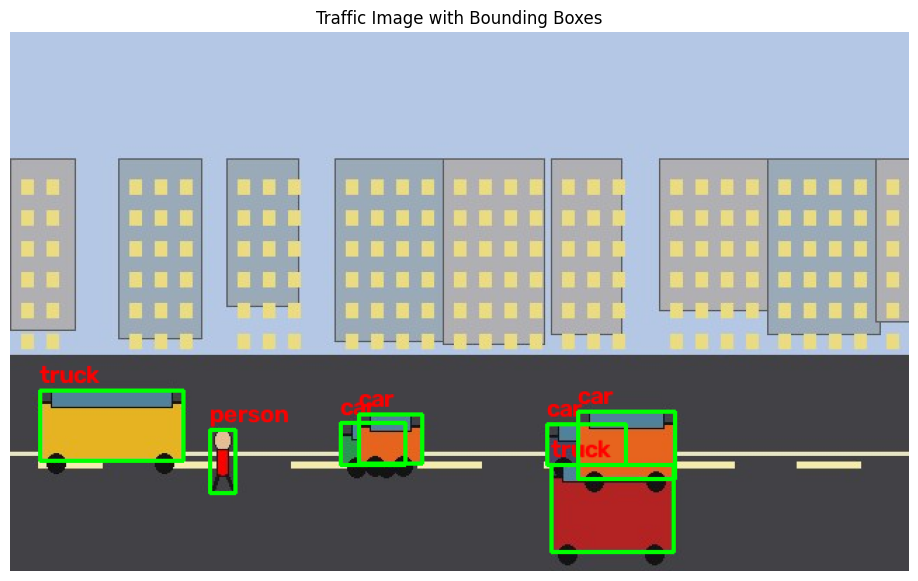

Image: traffic_rush_001.jpg
Total Objects: 7


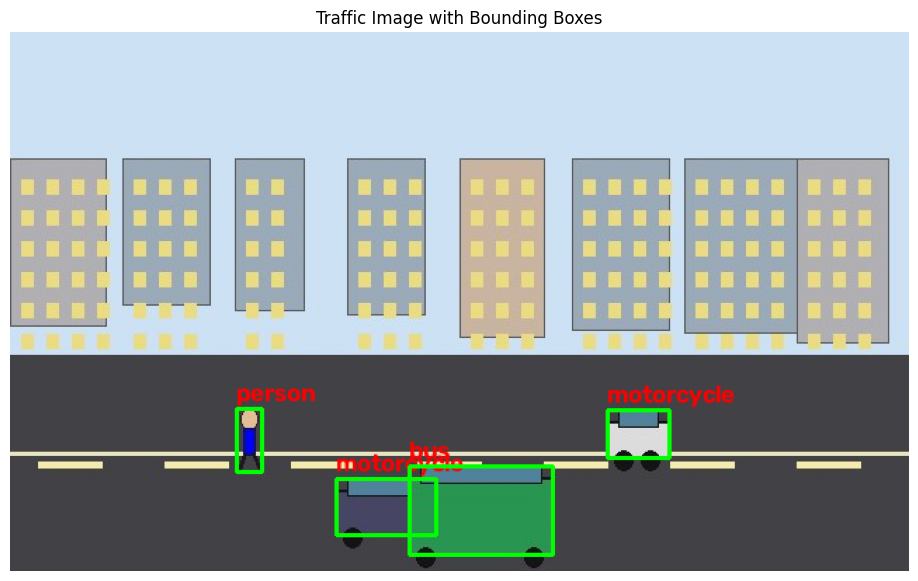

Image: traffic_rush_002.jpg
Total Objects: 4


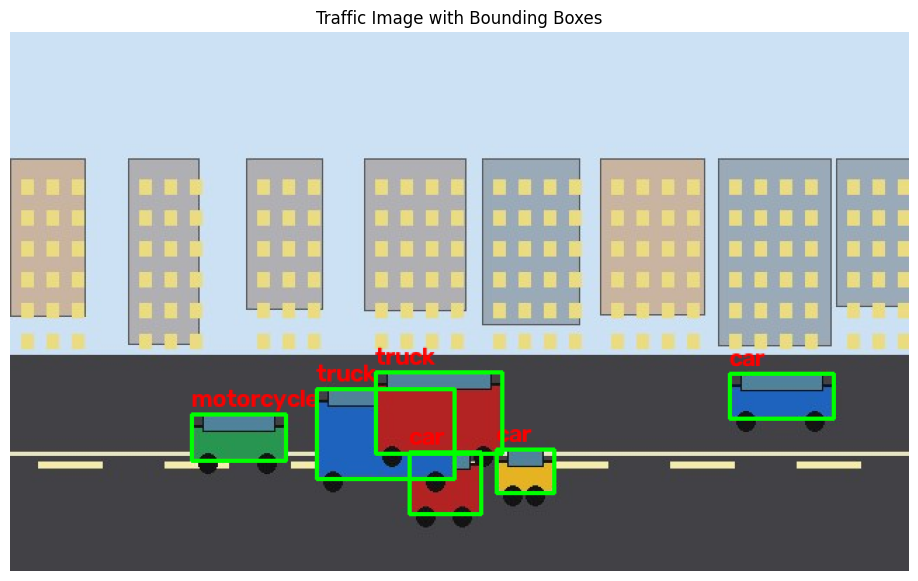

Image: traffic_rush_003.jpg
Total Objects: 6


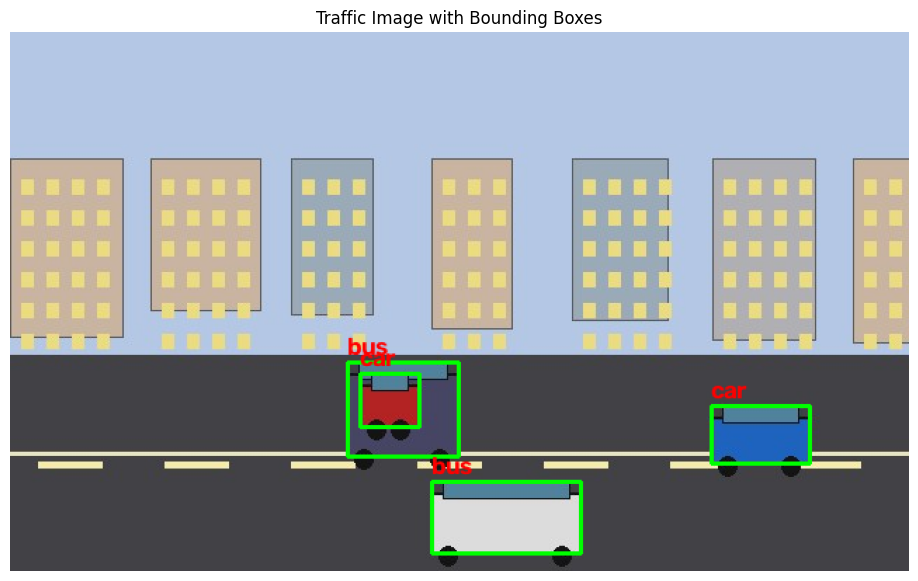

Image: traffic_rush_004.jpg
Total Objects: 4


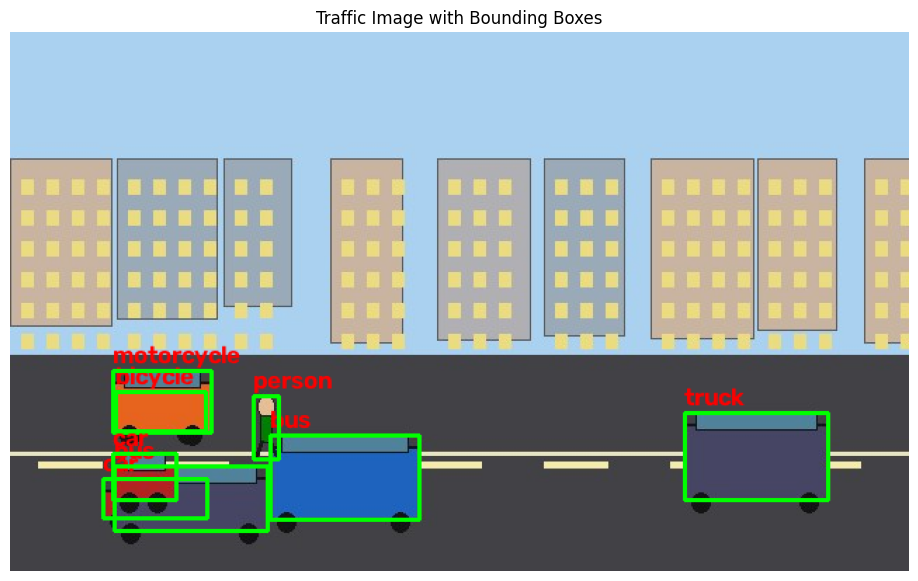

Image: traffic_rush_005.jpg
Total Objects: 8


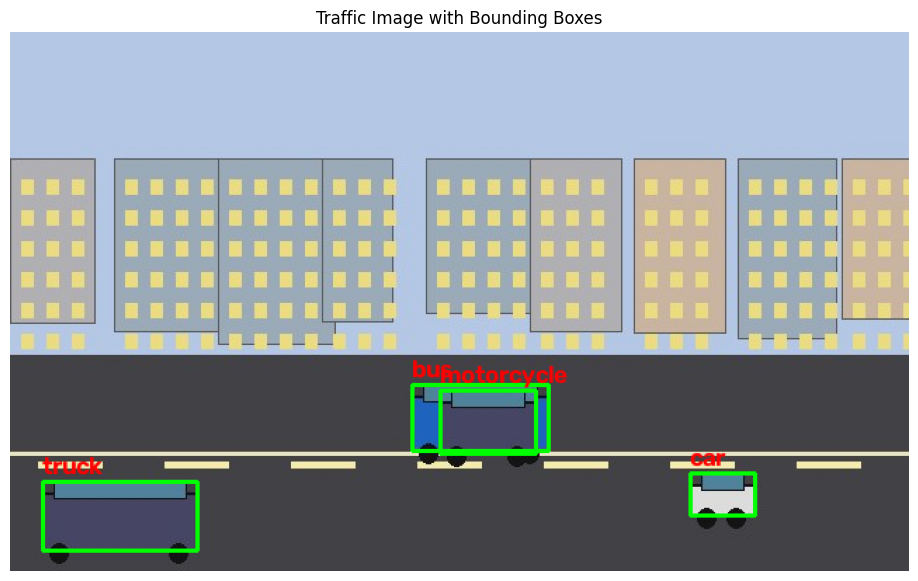

Image: traffic_rush_006.jpg
Total Objects: 4


In [16]:
sample_images = coco_data["images"][:6]

for img in sample_images:
    visualize_image(img["id"])

In [17]:
annotation_details = []

for ann in coco_data["annotations"]:

    x, y, width, height = ann["bbox"]

    annotation_details.append({

        "Image ID": ann["image_id"],

        "Category": category_names[ann["category_id"]],

        "X Coordinate": x,

        "Y Coordinate": y,

        "Width": width,

        "Height": height

    })

annotation_df = pd.DataFrame(annotation_details)

print(annotation_df.head(10))

   Image ID    Category  X Coordinate  Y Coordinate  Width  Height
0         1       truck            21           255    102      50
1         1         car           235           278     46      30
2         1         car           382           279     56      29
3         1      person           142           283     18      45
4         1       truck           385           308     87      62
5         1         car           248           272     45      35
6         1         car           404           270     69      48
7         2  motorcycle           425           269     44      34
8         2  motorcycle           232           318     71      40
9         2      person           161           268     18      45


In [18]:
annotation_df["Box Area"] = (
    annotation_df["Width"] *
    annotation_df["Height"]
)

print(annotation_df.head(10))

   Image ID    Category  X Coordinate  Y Coordinate  Width  Height  Box Area
0         1       truck            21           255    102      50      5100
1         1         car           235           278     46      30      1380
2         1         car           382           279     56      29      1624
3         1      person           142           283     18      45       810
4         1       truck           385           308     87      62      5394
5         1         car           248           272     45      35      1575
6         1         car           404           270     69      48      3312
7         2  motorcycle           425           269     44      34      1496
8         2  motorcycle           232           318     71      40      2840
9         2      person           161           268     18      45       810


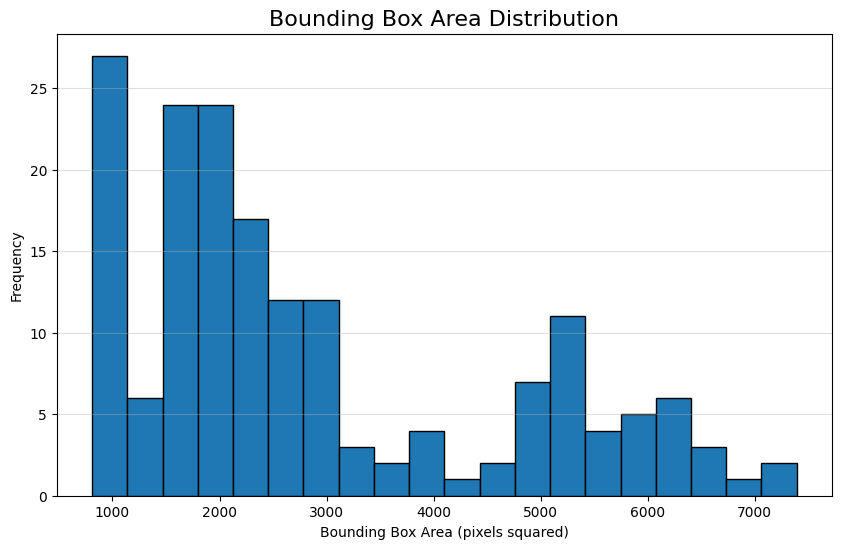

In [19]:
plt.figure(figsize=(10, 6))

plt.hist(
    annotation_df["Box Area"],
    bins=20,
    edgecolor="black"
)

plt.title("Bounding Box Area Distribution", fontsize=16)
plt.xlabel("Bounding Box Area (pixels squared)")
plt.ylabel("Frequency")

plt.grid(axis="y", alpha=0.4)
plt.show()

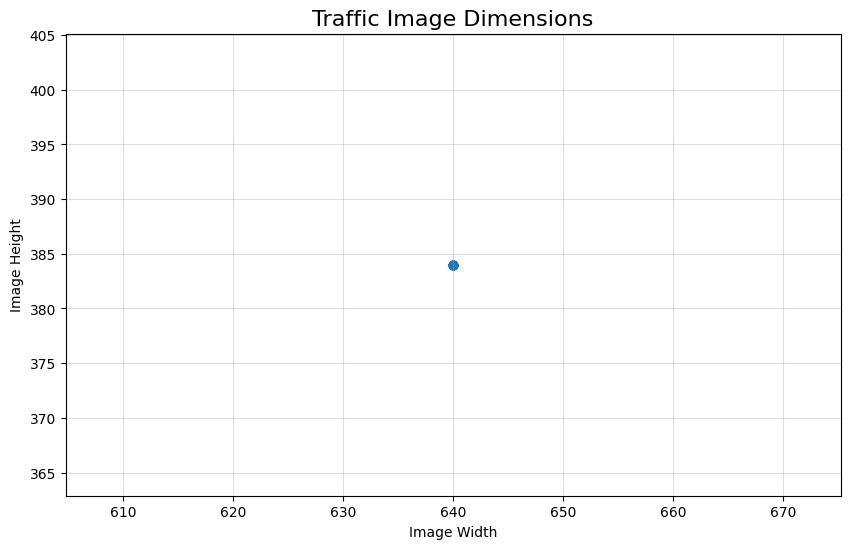

In [20]:
image_sizes = pd.DataFrame(coco_data["images"])

plt.figure(figsize=(10, 6))

plt.scatter(
    image_sizes["width"],
    image_sizes["height"],
    alpha=0.6
)

plt.title("Traffic Image Dimensions", fontsize=16)
plt.xlabel("Image Width")
plt.ylabel("Image Height")

plt.grid(alpha=0.4)
plt.show()

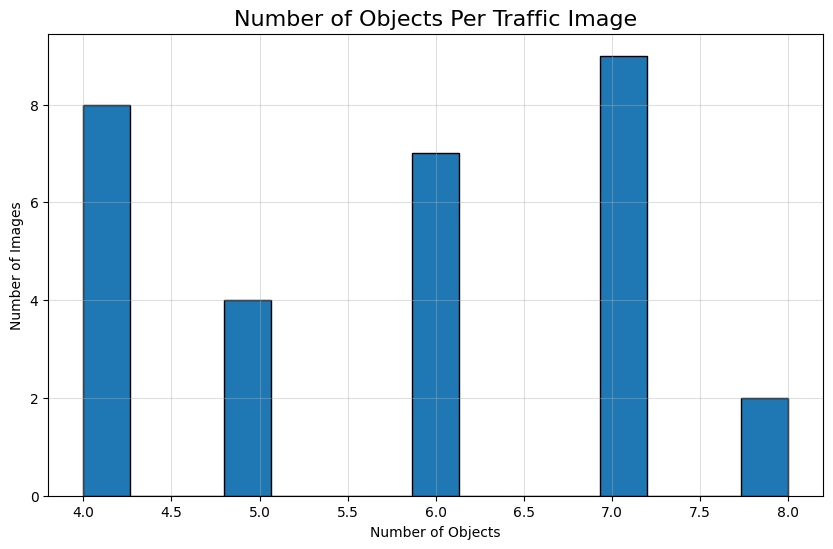

In [21]:
objects_per_image = annotation_df.groupby(
    "Image ID"
).size()

plt.figure(figsize=(10, 6))

plt.hist(
    objects_per_image,
    bins=15,
    edgecolor="black"
)

plt.title("Number of Objects Per Traffic Image", fontsize=16)
plt.xlabel("Number of Objects")
plt.ylabel("Number of Images")

plt.grid(alpha=0.4)
plt.show()

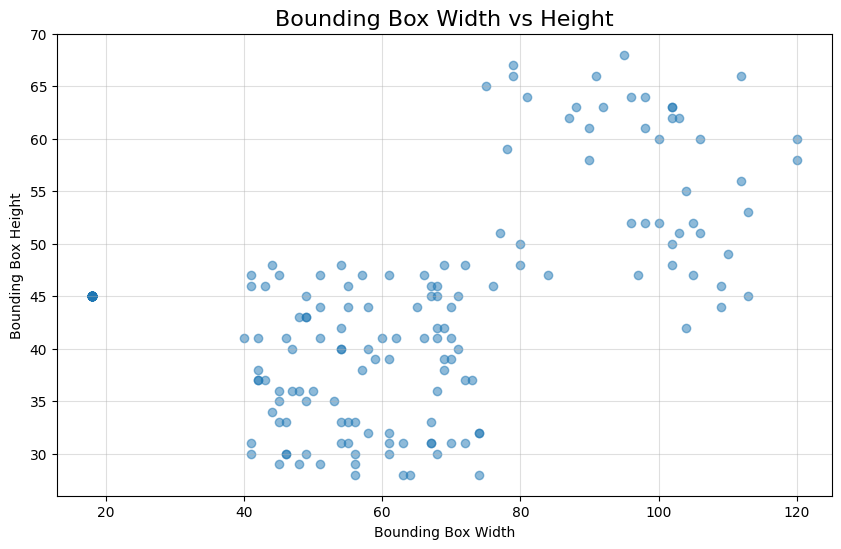

In [22]:
plt.figure(figsize=(10, 6))

plt.scatter(
    annotation_df["Width"],
    annotation_df["Height"],
    alpha=0.5
)

plt.title("Bounding Box Width vs Height", fontsize=16)
plt.xlabel("Bounding Box Width")
plt.ylabel("Bounding Box Height")

plt.grid(alpha=0.4)
plt.show()

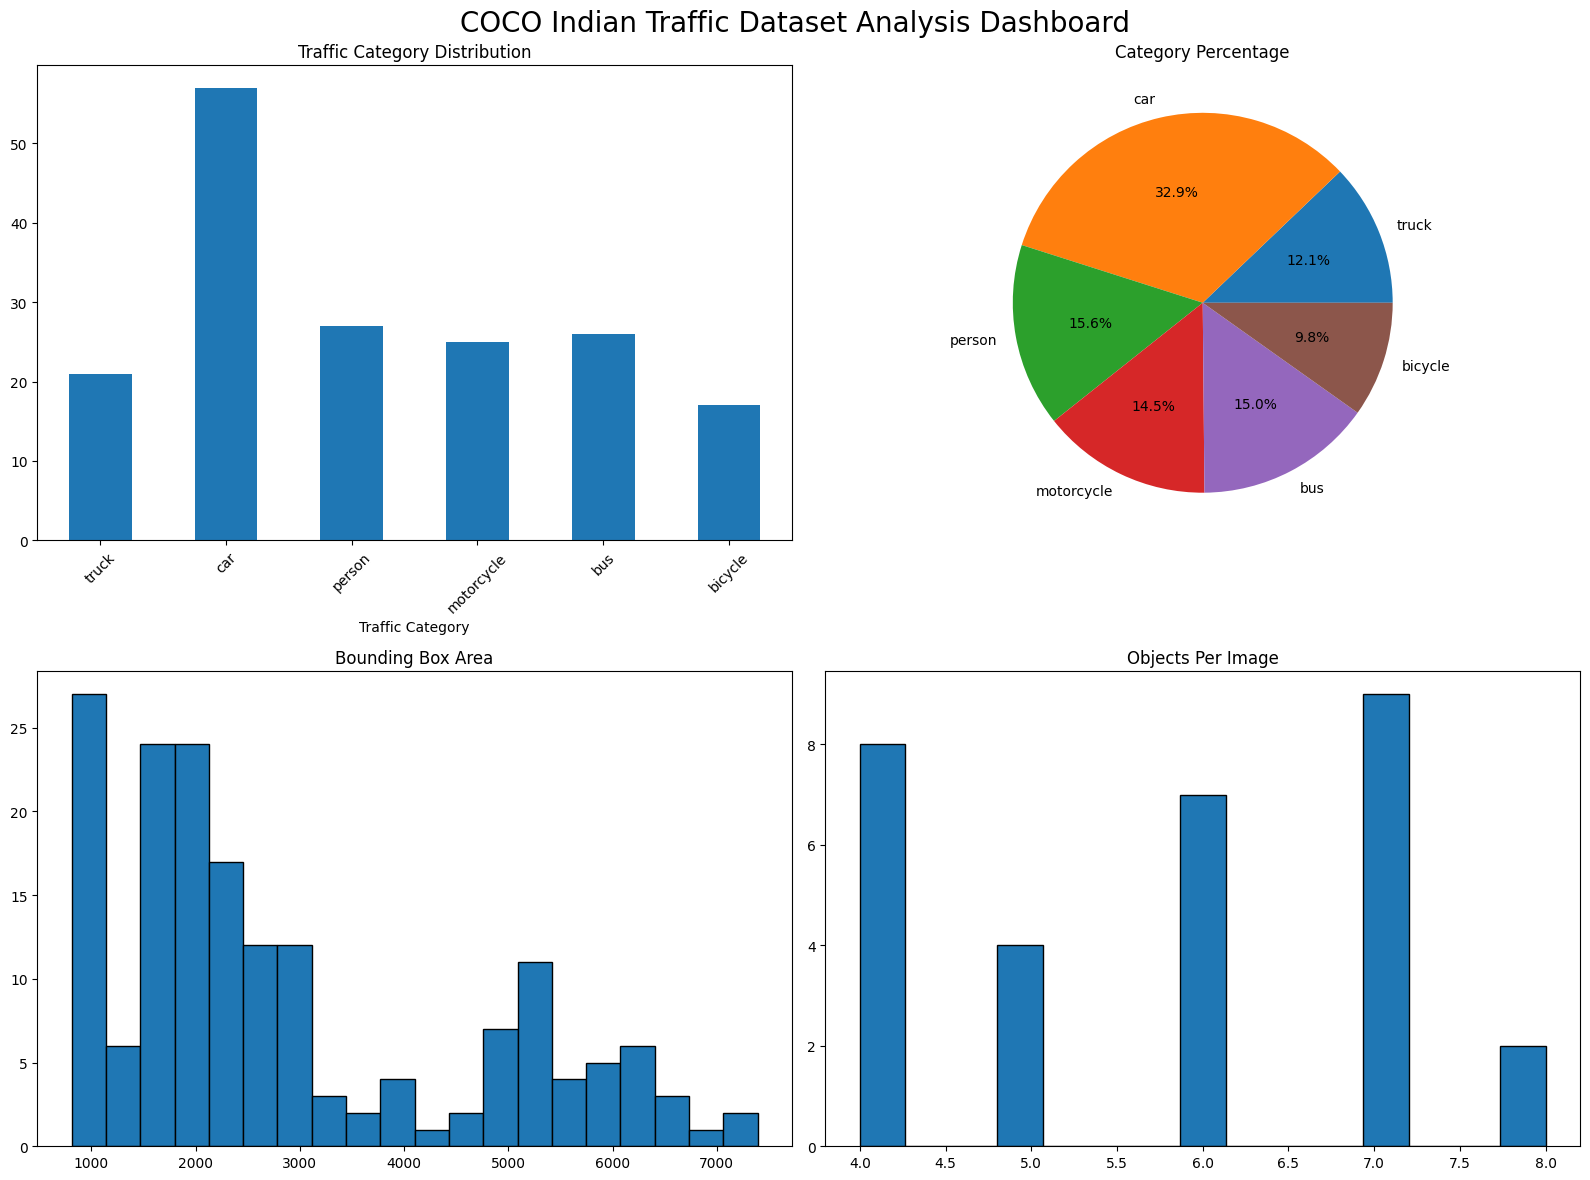

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Category distribution
df.plot(
    kind="bar",
    x="Traffic Category",
    y="Number of Objects",
    ax=axes[0, 0],
    legend=False
)

axes[0, 0].set_title("Traffic Category Distribution")
axes[0, 0].tick_params(axis="x", rotation=45)

# Category pie chart
axes[0, 1].pie(
    df["Number of Objects"],
    labels=df["Traffic Category"],
    autopct="%1.1f%%"
)

axes[0, 1].set_title("Category Percentage")

# Bounding box area
axes[1, 0].hist(
    annotation_df["Box Area"],
    bins=20,
    edgecolor="black"
)

axes[1, 0].set_title("Bounding Box Area")

# Objects per image
axes[1, 1].hist(
    objects_per_image,
    bins=15,
    edgecolor="black"
)

axes[1, 1].set_title("Objects Per Image")

plt.suptitle(
    "COCO Indian Traffic Dataset Analysis Dashboard",
    fontsize=20
)

plt.tight_layout()
plt.show()

In [24]:
output_file = "/content/traffic_annotation_results.csv"

annotation_df.to_csv(output_file, index=False)

print("CSV file saved successfully!")

CSV file saved successfully!


In [25]:
files.download(output_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
dashboard_path = "/content/traffic_dashboard.png"

fig.savefig(
    dashboard_path,
    dpi=300,
    bbox_inches="tight"
)

print("Dashboard saved successfully!")

Dashboard saved successfully!


In [27]:
files.download(dashboard_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
print("=" * 55)
print("COCO DATASET EXPLORATION - PROJECT REPORT")
print("=" * 55)

print("Total Images:", len(coco_data["images"]))

print("Total Annotations:", len(coco_data["annotations"]))

print("Total Categories:", len(coco_data["categories"]))

print("Total Image Files Found:", len(image_map))

print("\nCATEGORY DISTRIBUTION")

print(df.to_string(index=False))

print("\nTOTAL BOUNDING BOXES:", len(annotation_df))

print("\nPROJECT COMPLETED SUCCESSFULLY!")
print("=" * 55)

COCO DATASET EXPLORATION - PROJECT REPORT
Total Images: 30
Total Annotations: 173
Total Categories: 6
Total Image Files Found: 30

CATEGORY DISTRIBUTION
Traffic Category  Number of Objects
           truck                 21
             car                 57
          person                 27
      motorcycle                 25
             bus                 26
         bicycle                 17

TOTAL BOUNDING BOXES: 173

PROJECT COMPLETED SUCCESSFULLY!
